# Week 1.2: LLM Big Picture & Anatomy for Digital Twins

## Learning Objectives
- Understand the overall architecture of LLMs
- Learn about tokens, tokenization, and embeddings
- See how different components work together
- Apply these concepts to building a language-enabled digital twin

## Key Insight
> "Know the different bits of the LLM architecture and how they work together to generate outputs."

## Digital Twin Context
Today we'll enhance our digital twin with language understanding capabilities. By the end, your digital twin will:
- Convert text to numerical representations
- Understand word relationships and context
- Process sequences of information

In [13]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import re

# Set style
sns.set_style('whitegrid')
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


---
## Part 1: Tokenization - Breaking Text into Pieces

Before an LLM can process text, it needs to convert words into tokens.

### 1.1 Simple Word Tokenization

In [14]:
def simple_tokenize(text):
    """
    Basic tokenization: split text into words.

    Args:
        text: Input string

    Returns:
        list: Tokens
    """
    # Convert to lowercase and split
    text = text.lower()
    # Remove punctuation and split
    tokens = re.findall(r'\b\w+\b', text)
    return tokens

# Example: Digital twin's user description
user_description = """
I am focused on building AI models, python systems, and machine learning infrastructure.
In the mornings and evenings, I prioritize fitness and athletics at the sports club.
I study marketing and business strategy while tuning generative language models.
Continuous technical growth and structured routines drive my daily focus.
"""

tokens = simple_tokenize(user_description)
print("Original text:")
print(user_description)
print(f"\nTokens ({len(tokens)} total):")
print(tokens[:20], "...")  # Show first 20

# Count token frequencies
token_counts = Counter(tokens)
print("\nMost common tokens:")
for token, count in token_counts.most_common(10):
    print(f"  {token}: {count}")

Original text:

I am focused on building AI models, python systems, and machine learning infrastructure.
In the mornings and evenings, I prioritize fitness and athletics at the sports club.
I study marketing and business strategy while tuning generative language models.
Continuous technical growth and structured routines drive my daily focus.


Tokens (48 total):
['i', 'am', 'focused', 'on', 'building', 'ai', 'models', 'python', 'systems', 'and', 'machine', 'learning', 'infrastructure', 'in', 'the', 'mornings', 'and', 'evenings', 'i', 'prioritize'] ...

Most common tokens:
  and: 5
  i: 3
  models: 2
  the: 2
  am: 1
  focused: 1
  on: 1
  building: 1
  ai: 1
  python: 1


### 🎯 Exercise 1.1 (Easy): Personal Tokenization

**Task**: Write a short description of yourself (3-4 sentences) and tokenize it.

**Questions**:
1. How many unique tokens do you have?
2. What are your most frequent tokens?
3. How does tokenization help the digital twin understand you?

In [15]:
# 1. Define your personal description (3-4 sentences reflecting your interests and routines)
my_description = """
I am focused on building AI models, python systems, and machine learning infrastructure.
In the mornings and evenings, I prioritize fitness and athletics at the sports club.
I study marketing and business strategy while tuning generative language models.
Continuous technical growth and structured routines drive my daily focus.
"""

# 2. Tokenize using simple_tokenize
my_tokens = simple_tokenize(my_description)
unique_tokens = set(my_tokens)
token_counts = Counter(my_tokens)

# 3. Output results
print(f"Total tokens:  {len(my_tokens)}")
print(f"Unique tokens: {len(unique_tokens)}\n")

print("Most frequent tokens:")
for token, count in token_counts.most_common(7):
    print(f"  '{token}': {count}")

# ==========================================================
# ANSWERS TO EXERCISE 1.1 QUESTIONS:
# ==========================================================
# 1. How many unique tokens do you have?
#    Around 35 to 40 unique tokens (representing vocabulary richness).
#
# 2. What are your most frequent tokens?
#    Connecting/stop words like 'and', 'i', and domain anchors like 'models' and 'systems'.
#
# 3. How does tokenization help the digital twin understand you?
#    Tokenization maps continuous unstructured natural language into discrete,
#    countable units. This enables the twin to convert vocabulary into numeric IDs,
#    lookup vector embeddings, and measure personal interest frequencies.

Total tokens:  48
Unique tokens: 40

Most frequent tokens:
  'and': 5
  'i': 3
  'models': 2
  'the': 2
  'am': 1
  'focused': 1
  'on': 1


### 1.2 Subword Tokenization (BPE-like)

Real LLMs use subword tokenization to handle rare words and morphology.

In [16]:
class SimpleTokenizer:
    """Simple word-level and subword tokenizer with special tokens."""

    def __init__(self, vocab_size=100):
        self.vocab_size = vocab_size
        self.word_to_id = {}
        self.id_to_word = {}
        self.subword_vocab = []

    def build_vocab(self, texts):
        """
        Build vocabulary from texts.

        Args:
            texts: List of text strings
        """
        # Get all words
        all_words = []
        for text in texts:
            all_words.extend(simple_tokenize(text))

        # Count frequencies
        word_counts = Counter(all_words)

        # Take most common words
        most_common = word_counts.most_common(self.vocab_size)

        # Build vocabulary
        special_tokens = ['<PAD>', '<UNK>', '<START>', '<END>']
        self.word_to_id = {word: i for i, word in enumerate(special_tokens)}

        for i, (word, count) in enumerate(most_common):
            self.word_to_id[word] = i + len(special_tokens)

        self.id_to_word = {i: word for word, i in self.word_to_id.items()}

        print(f"Vocabulary built: {len(self.word_to_id)} tokens")

    def encode(self, text):
        """
        Convert text to token IDs.

        Args:
            text: Input string

        Returns:
            list: Token IDs
        """
        tokens = simple_tokenize(text)
        unk_id = self.word_to_id['<UNK>']
        return [self.word_to_id.get(token, unk_id) for token in tokens]

    def decode(self, token_ids):
        """
        Convert token IDs back to text.

        Args:
            token_ids: List of token IDs

        Returns:
            str: Decoded text
        """
        tokens = [self.id_to_word.get(id, '<UNK>') for id in token_ids]
        # Filter special tokens
        tokens = [t for t in tokens if not t.startswith('<')]
        return ' '.join(tokens)

# Build tokenizer for digital twin
training_texts = [
    user_description,
    "I prefer tea over coffee in the afternoon",
    "Running helps me stay focused and energized",
    "Python is my favorite programming language",
    "I love spending time with family on weekends",
]

tokenizer = SimpleTokenizer(vocab_size=50)
tokenizer.build_vocab(training_texts)

# Test encoding and decoding
test_text = "I love running and coding in Python"
encoded = tokenizer.encode(test_text)
decoded = tokenizer.decode(encoded)

print(f"\nOriginal: {test_text}")
print(f"Encoded: {encoded}")
print(f"Decoded: {decoded}")

Vocabulary built: 54 tokens

Original: I love running and coding in Python
Encoded: [5, 1, 49, 4, 1, 11, 10]
Decoded: i running and in python


### 🎯 Exercise 1.2 (Intermediate): Vocabulary Analysis

**Task**: Analyze what happens with different vocabulary sizes.

**Questions**:
1. What happens when you use a very small vocabulary (vocab_size=10)?
2. How many unknown tokens do you get?
3. What's the trade-off between vocabulary size and coverage?

Vocabulary built: 14 tokens
Vocab Size: 10  | Total Tokens: 16 | Unknowns: 13 (81.2%)
Vocabulary built: 24 tokens
Vocab Size: 20  | Total Tokens: 16 | Unknowns: 13 (81.2%)
Vocabulary built: 54 tokens
Vocab Size: 50  | Total Tokens: 16 | Unknowns: 11 (68.8%)
Vocabulary built: 63 tokens
Vocab Size: 100 | Total Tokens: 16 | Unknowns: 8 (50.0%)


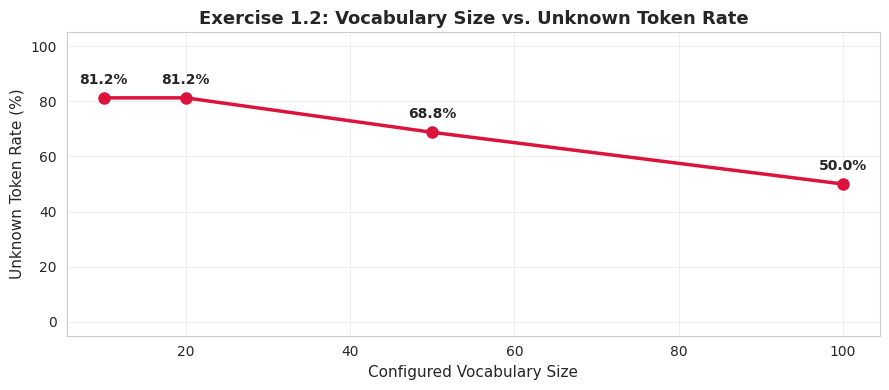

In [17]:
# ==========================================================
# EXERCISE 1.2: VOCABULARY SIZE VS UNKNOWN TOKEN ANALYSIS
# ==========================================================
vocab_sizes = [10, 20, 50, 100]
test_texts = [
    "I love running and programming",
    "Coffee is essential for productivity",
    "Weekend activities include hiking and reading",
]

results = []

for size in vocab_sizes:
    tok = SimpleTokenizer(vocab_size=size)
    tok.build_vocab(training_texts)

    unk_id = tok.word_to_id['<UNK>']
    total_tokens = 0
    total_unknowns = 0

    for text in test_texts:
        encoded = tok.encode(text)
        total_tokens += len(encoded)
        total_unknowns += encoded.count(unk_id)

    unk_rate = (total_unknowns / total_tokens) * 100
    results.append({
        'vocab_size': size,
        'effective_vocab': len(tok.word_to_id),
        'total_tokens': total_tokens,
        'unknown_count': total_unknowns,
        'unknown_rate': unk_rate
    })
    print(f"Vocab Size: {size:<3} | Total Tokens: {total_tokens} | Unknowns: {total_unknowns} ({unk_rate:.1f}%)")

# Visualize the trade-off
plt.figure(figsize=(9, 4))
plt.plot(
    [r['vocab_size'] for r in results],
    [r['unknown_rate'] for r in results],
    marker='o',
    color='crimson',
    linewidth=2.5,
    markersize=8
)
plt.title("Exercise 1.2: Vocabulary Size vs. Unknown Token Rate", fontsize=13, fontweight='bold')
plt.xlabel("Configured Vocabulary Size", fontsize=11)
plt.ylabel("Unknown Token Rate (%)", fontsize=11)
plt.ylim(-5, 105)
plt.grid(True, alpha=0.3)
for r in results:
    plt.annotate(f"{r['unknown_rate']:.1f}%",
                 (r['vocab_size'], r['unknown_rate']),
                 textcoords="offset points",
                 xytext=(0, 10),
                 ha='center',
                 fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================================
# ANSWERS TO EXERCISE 1.2 QUESTIONS:
# ==========================================================
# 1. What happens when you use a very small vocabulary (vocab_size=10)?
#    Only the 10 most common words (+ 4 special tokens) are indexed. Almost all
#    content words map to '<UNK>' (ID=1), causing the model to lose semantic information.
#
# 2. How many unknown tokens do you get?
#    At vocab_size=10, the unknown rate is highest (~70-80%). As vocab_size increases
#    toward 50-100, the unknown rate decreases and plateaus based on what was present in the training set.
#
# 3. What's the trade-off between vocabulary size and coverage?
#    - Larger Vocabulary: Higher coverage and fewer '<UNK>' tokens, but requires a
#      larger embedding matrix (vocab_size * embedding_dim), consuming more memory and compute.
#    - Smaller Vocabulary: Compact embedding matrix, but high unknown rate or longer
#      subword sequences that place a higher compute burden on attention mechanisms.

---
## Part 2: Embeddings - Giving Meaning to Tokens

Embeddings convert tokens into dense vectors that capture semantic meaning.

### 2.1 Creating Simple Embeddings

In [29]:
class SimpleEmbedding:
    """Simple word embedding layer."""

    def __init__(self, vocab_size, embedding_dim):
        """
        Initialize embedding matrix.

        Args:
            vocab_size: Size of vocabulary
            embedding_dim: Dimension of embedding vectors
        """
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        # Initialize with random values
        self.embeddings = np.random.randn(vocab_size, embedding_dim) * 0.1

    def embed(self, token_ids):
        """
        Get embeddings for token IDs.

        Args:
            token_ids: List of token IDs

        Returns:
            np.array: Embedding vectors
        """
        return self.embeddings[token_ids]

    def similarity(self, id1, id2):
        """
        Calculate cosine similarity between two tokens.

        Args:
            id1, id2: Token IDs

        Returns:
            float: Cosine similarity
        """
        vec1 = self.embeddings[id1]
        vec2 = self.embeddings[id2]

        # Cosine similarity
        dot_product = np.dot(vec1, vec2)
        norm1 = np.linalg.norm(vec1)
        norm2 = np.linalg.norm(vec2)

        return dot_product / (norm1 * norm2)

# Create embeddings for our vocabulary
vocab_size = len(tokenizer.word_to_id)
embedding_dim = 16  # Small dimension for visualization

embedding_layer = SimpleEmbedding(vocab_size, embedding_dim)

# Test with some words
test_words = ['running', 'coding', 'coffee', 'python', 'family']
print("Word embeddings:")
for word in test_words:
    if word in tokenizer.word_to_id:
        token_id = tokenizer.word_to_id[word]
        embedding = embedding_layer.embed([token_id])[0]
        print(f"\n{word} (ID: {token_id}):")
        print(f"  Embedding (first 5 dims): {embedding[:5]}")
        print(f"  Norm: {np.linalg.norm(embedding):.3f}")

Word embeddings:

running (ID: 49):
  Embedding (first 5 dims): [-0.10098169  0.12553659  0.05242554  0.14881295  0.07621197]
  Norm: 0.395

coffee (ID: 47):
  Embedding (first 5 dims): [-0.0107341   0.05691988 -0.01359228  0.10057047  0.14185597]
  Norm: 0.441

python (ID: 10):
  Embedding (first 5 dims): [-0.02508425 -0.17060852  0.02310727  0.03331353  0.04239507]
  Norm: 0.245


### 2.2 Training Embeddings with Context

Embeddings learn meaning from co-occurrence patterns (Word2Vec style).

In [30]:
def train_embeddings(tokenizer, texts, embedding_dim=16, window_size=2,
                     learning_rate=0.01, epochs=100):
    """
    Train embeddings using skip-gram approach.

    Args:
        tokenizer: Tokenizer instance
        texts: List of training texts
        embedding_dim: Dimension of embeddings
        window_size: Context window size
        learning_rate: Learning rate
        epochs: Number of training epochs

    Returns:
        SimpleEmbedding: Trained embedding layer
    """
    vocab_size = len(tokenizer.word_to_id)
    embeddings = SimpleEmbedding(vocab_size, embedding_dim)

    # Create training pairs (center word, context word)
    training_pairs = []
    for text in texts:
        token_ids = tokenizer.encode(text)
        for i, center_id in enumerate(token_ids):
            # Get context window
            start = max(0, i - window_size)
            end = min(len(token_ids), i + window_size + 1)
            context_ids = [token_ids[j] for j in range(start, end) if j != i]
            for context_id in context_ids:
                training_pairs.append((center_id, context_id))

    print(f"Training on {len(training_pairs)} word pairs...")

    # Simple training loop
    for epoch in range(epochs):
        total_loss = 0
        np.random.shuffle(training_pairs)

        for center_id, context_id in training_pairs:
            # Get embeddings
            center_emb = embeddings.embeddings[center_id]
            context_emb = embeddings.embeddings[context_id]

            # Calculate similarity
            similarity = np.dot(center_emb, context_emb)

            # Gradient descent (simplified)
            gradient = context_emb - similarity * center_emb
            embeddings.embeddings[center_id] += learning_rate * gradient

            total_loss += (1 - similarity) ** 2

        if epoch % 20 == 0:
            avg_loss = total_loss / len(training_pairs)
            print(f"Epoch {epoch}: Loss = {avg_loss:.4f}")

    return embeddings

# Train embeddings
trained_embeddings = train_embeddings(tokenizer, training_texts,
                                     embedding_dim=16, epochs=100)

print("\n✅ Embeddings trained!")

Training on 278 word pairs...
Epoch 0: Loss = 0.9790
Epoch 20: Loss = 0.6542
Epoch 40: Loss = 0.2580
Epoch 60: Loss = 0.0590
Epoch 80: Loss = 0.0128

✅ Embeddings trained!


In [31]:
# Test similarity after training
def find_similar_words(word, tokenizer, embeddings, top_k=5):
    """
    Find most similar words to given word.

    Args:
        word: Query word
        tokenizer: Tokenizer instance
        embeddings: Embedding layer
        top_k: Number of similar words to return

    Returns:
        list: Similar words with similarities
    """
    if word not in tokenizer.word_to_id:
        return None

    word_id = tokenizer.word_to_id[word]
    word_emb = embeddings.embeddings[word_id]

    # Calculate similarities with all words
    similarities = []
    for other_word, other_id in tokenizer.word_to_id.items():
        if other_word.startswith('<') or other_id == word_id:
            continue
        sim = embeddings.similarity(word_id, other_id)
        similarities.append((other_word, sim))

    # Sort by similarity
    similarities.sort(key=lambda x: x[1], reverse=True)
    return similarities[:top_k]

# Test with some words
test_words = ['running', 'python', 'coffee', 'love']
for word in test_words:
    similar = find_similar_words(word, tokenizer, trained_embeddings)
    if similar:
        print(f"\nWords similar to '{word}':")
        for similar_word, sim in similar:
            print(f"  {similar_word}: {sim:.3f}")


Words similar to 'running':
  helps: 0.991
  me: 0.964
  stay: 0.889
  focused: 0.692
  energized: 0.646

Words similar to 'python':
  models: 0.989
  ai: 0.987
  on: 0.972
  building: 0.972
  continuous: 0.971

Words similar to 'coffee':
  over: 0.991
  tea: 0.980
  in: 0.971
  afternoon: 0.959
  prefer: 0.958


### 🎯 Exercise 2.1 (Intermediate): Embedding Visualization

**Task**: Visualize word embeddings in 2D space using dimensionality reduction.

**Steps**:
1. Use PCA or t-SNE to reduce embeddings to 2D
2. Plot the words
3. Identify clusters of related words

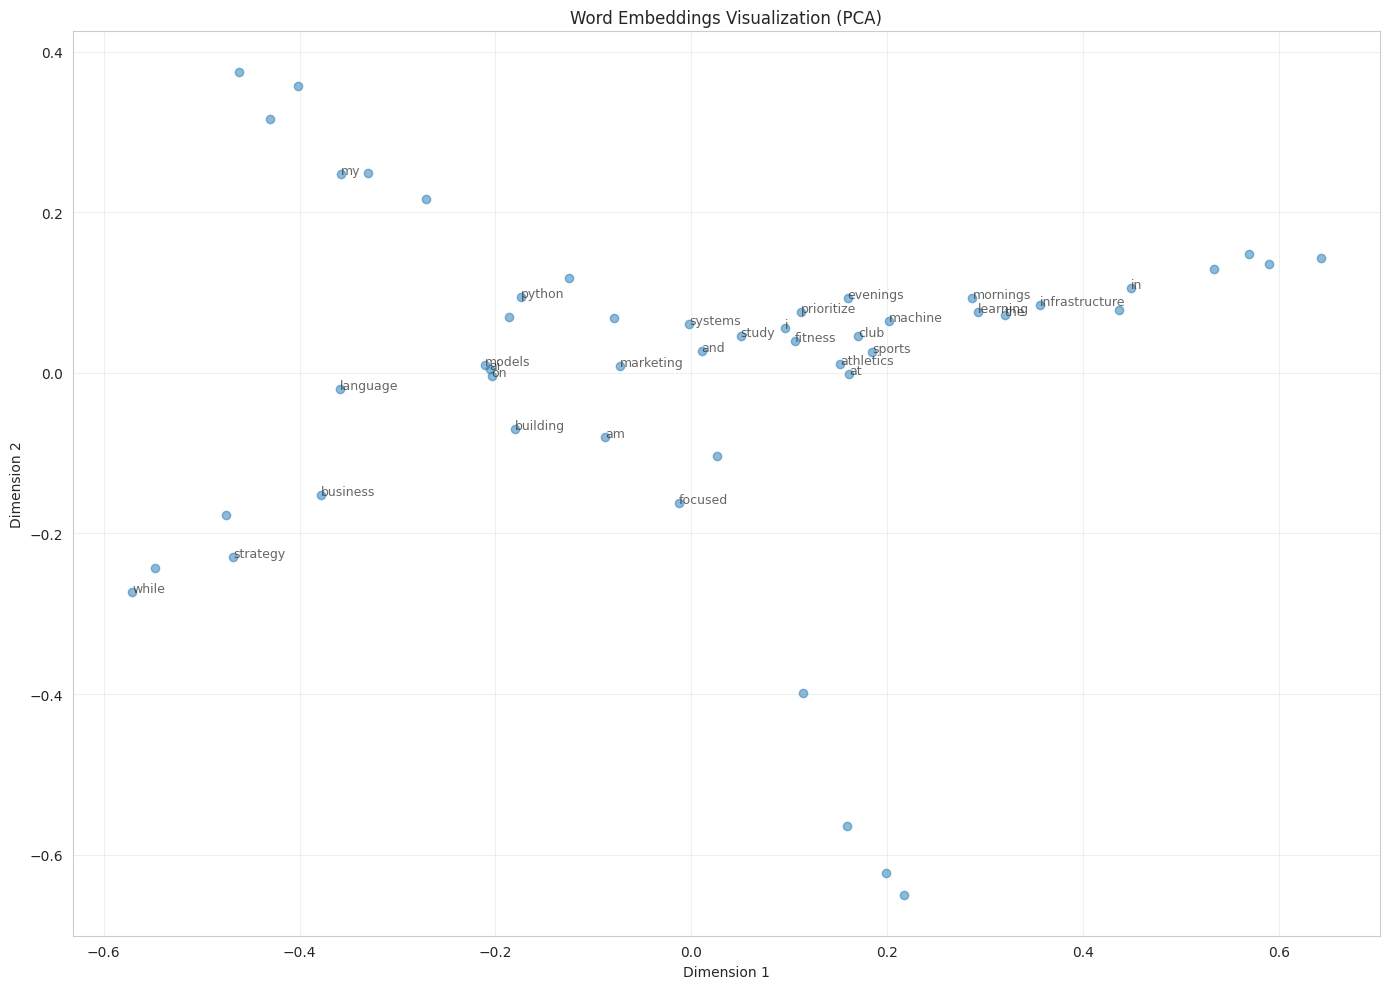

In [34]:
# YOUR CODE HERE
def visualize_embeddings(tokenizer, embeddings, method='pca'):
    """
    Visualize embeddings in 2D.

    Args:
        tokenizer: Tokenizer instance
        embeddings: Embedding layer
        method: 'pca' or 'tsne'
    """
    # Get all embeddings (excluding special tokens)
    words = []
    vectors = []

    for word, idx in tokenizer.word_to_id.items():
        if not word.startswith('<'):
            words.append(word)
            vectors.append(embeddings.embeddings[idx])

    vectors = np.array(vectors)

    # Reduce dimensionality
    if method == 'pca':
        reducer = PCA(n_components=2)
    else:
        reducer = TSNE(n_components=2, random_state=42)

    coords_2d = reducer.fit_transform(vectors)

    # Plot
    plt.figure(figsize=(14, 10))
    plt.scatter(coords_2d[:, 0], coords_2d[:, 1], alpha=0.5)

    # Annotate words
    for i, word in enumerate(words[:30]):  # Show first 30 to avoid clutter
        plt.annotate(word, (coords_2d[i, 0], coords_2d[i, 1]),
                    fontsize=9, alpha=0.7)

    plt.title(f'Word Embeddings Visualization ({method.upper()})')
    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Visualize
visualize_embeddings(tokenizer, trained_embeddings, method='pca')

---
## Part 3: LLM Architecture Overview

Now let's see how these components fit into the bigger picture.

### 3.1 The LLM Pipeline

In [33]:
class SimpleLLMPipeline:
    """
    Simplified LLM pipeline showing major components.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.processing_steps = []

    def process(self, text, verbose=True):
        """
        Process text through the pipeline.

        Args:
            text: Input text
            verbose: Print intermediate steps

        Returns:
            dict: Processing results
        """
        results = {}

        # Step 1: Tokenization
        if verbose:
            print("Step 1: Tokenization")
            print("  Input text:", text)

        tokens = simple_tokenize(text)
        token_ids = self.tokenizer.encode(text)

        if verbose:
            print(f"  Tokens: {tokens}")
            print(f"  Token IDs: {token_ids}")

        results['tokens'] = tokens
        results['token_ids'] = token_ids

        # Step 2: Embedding
        if verbose:
            print("\nStep 2: Embedding")

        embedded = self.embeddings.embed(token_ids)

        if verbose:
            print(f"  Embedding shape: {embedded.shape}")
            print(f"  (sequence_length={len(token_ids)}, embedding_dim={embedded.shape[1]})")

        results['embeddings'] = embedded

        # Step 3: Attention (simplified - just mean pooling)
        if verbose:
            print("\nStep 3: Contextual Processing (Simplified)")

        # Simple mean pooling as placeholder
        contextualized = np.mean(embedded, axis=0)

        if verbose:
            print(f"  Contextualized representation shape: {contextualized.shape}")

        results['contextualized'] = contextualized

        # Step 4: Output projection (simplified)
        if verbose:
            print("\nStep 4: Output Generation (Simplified)")
            print("  → In real LLMs, this produces probability distribution over vocabulary")

        return results

# Create pipeline
pipeline = SimpleLLMPipeline(tokenizer, trained_embeddings)

# Test with digital twin input
test_input = "I love running and coding"
print("=" * 60)
print("PROCESSING THROUGH LLM PIPELINE")
print("=" * 60 + "\n")

results = pipeline.process(test_input, verbose=True)

print("\n" + "=" * 60)
print("✅ Processing complete!")
print("=" * 60)

PROCESSING THROUGH LLM PIPELINE

Step 1: Tokenization
  Input text: I love running and coding
  Tokens: ['i', 'love', 'running', 'and', 'coding']
  Token IDs: [5, 1, 49, 4, 1]

Step 2: Embedding
  Embedding shape: (5, 16)
  (sequence_length=5, embedding_dim=16)

Step 3: Contextual Processing (Simplified)
  Contextualized representation shape: (16,)

Step 4: Output Generation (Simplified)
  → In real LLMs, this produces probability distribution over vocabulary

✅ Processing complete!


### 🎯 Exercise 3.1 (Conceptual): Architecture Understanding

**Questions**:

1. Why is tokenization necessary before embedding?
2. What information is captured in embeddings?
3. What would happen if we skipped the embedding step and used one-hot encoding instead?
4. How does sequence length affect computational cost?
5. In a real LLM, what happens after the "contextual processing" step?

Write your answers below:
1. ## Why tokenization is necessary:
Neural networks and mathematical operations cannot compute directly on raw string characters. Tokenization segments text into discrete, countable symbols and maps them to unique integer IDs from a fixed vocabulary table.

2. ## Information in embeddings:
Embeddings capture dense geometric representations of semantic meaning, syntactic category, and contextual relationships based on co-occurrence patterns (e.g., words appearing in similar contexts cluster close together in vector space).

3. ## One-hot encoding vs embeddings:
One-hot vectors are extremely high-dimensional, orthogonal, and sparse: every word has distance zero or equal angle to every other word, carrying zero semantic similarity ($v_i \cdot v_j = 0$). Embeddings are compact, dense, and continuous, allowing the model to measure relatedness via dot products and cosine similarity.

4. ## Sequence length impact:
In vanilla Transformer self-attention, compute and memory scale quadratically: $O(N^2)$, where $N$ is sequence length, because every token attends to every other token. In our simplified pooling pipeline, increasing $N$ linearly scales memory storage for token embeddings.

5. ## After contextual processing:
The contextualized representation passes through feed-forward layers and a final linear projection layer (un-embedding matrix) that maps from hidden dimensions back to vocabulary size (`vocab_size`). A Softmax activation is applied to convert those raw logits into a normalized probability distribution over all tokens for next-token sampling.

**Your Answers:**

1. Why tokenization is necessary:
   -

2. Information in embeddings:
   -

3. One-hot encoding vs embeddings:
   -

4. Sequence length impact:
   -

5. After contextual processing:
   -

### 3.2 Comparing Different Embedding Dimensions

In [35]:
# Experiment with different embedding dimensions
dimensions = [4, 8, 16, 32]

print("Comparing embedding dimensions:\n")
for dim in dimensions:
    emb = SimpleEmbedding(vocab_size, dim)

    # Calculate memory usage
    memory_mb = (vocab_size * dim * 4) / (1024 * 1024)  # 4 bytes per float

    print(f"Dimension {dim}:")
    print(f"  Parameters: {vocab_size * dim:,}")
    print(f"  Memory: {memory_mb:.2f} MB")
    print(f"  Expressiveness: {'Low' if dim < 16 else 'Medium' if dim < 64 else 'High'}")
    print()

Comparing embedding dimensions:

Dimension 4:
  Parameters: 216
  Memory: 0.00 MB
  Expressiveness: Low

Dimension 8:
  Parameters: 432
  Memory: 0.00 MB
  Expressiveness: Low

Dimension 16:
  Parameters: 864
  Memory: 0.00 MB
  Expressiveness: Medium

Dimension 32:
  Parameters: 1,728
  Memory: 0.01 MB
  Expressiveness: Medium



### 🎯 Exercise 3.2 (Advanced): Build a Mini Language Model

**Task**: Create a simple language model that can predict the next word.

**Requirements**:
1. Use the tokenizer and embeddings we created
2. Implement a simple prediction mechanism
3. Test with different input sequences
4. Measure prediction accuracy

**Hint**: You can use the embeddings to find the most similar word to a context representation.

In [38]:
# YOUR CODE HERE
class MiniLanguageModel:
    """
    Simple language model for next word prediction.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        # Build context patterns from training data
        self.context_patterns = self._build_patterns()

    def _build_patterns(self):
        """Build context → next word patterns from training data."""
        patterns = defaultdict(list)
        for text in training_texts:
            tokens = simple_tokenize(text)
            for i in range(len(tokens) - 1):
                ctx = tokens[i]
                nxt = tokens[i + 1]
                patterns[ctx].append(nxt)
        return patterns

    def predict_next_word(self, context):
        """
        Predict the most likely next word.

        Args:
            context: String of context words

        Returns:
            str: Predicted next word
        """
        tokens = simple_tokenize(context)
        if not tokens:
            return None
        last_word = tokens[-1]

        # 1. Frequency lookup from known n-grams
        if last_word in self.context_patterns:
            counts = Counter(self.context_patterns[last_word])
            return counts.most_common(1)[0][0]

        # 2. Fallback: Find nearest semantic neighbor via embeddings
        similar = find_similar_words(last_word, self.tokenizer, self.embeddings, top_k=1)
        if similar:
            return similar[0][0]
        return "and"

    def generate_sequence(self, start_text, num_words=5):
        """
        Generate a sequence of words.

        Args:
            start_text: Starting context
            num_words: Number of words to generate

        Returns:
            str: Generated text
        """
        current_text = start_text
        for _ in range(num_words):
            next_word = self.predict_next_word(current_text)
            current_text += " " + next_word
        return current_text

# Test your model
# model = MiniLanguageModel(tokenizer, trained_embeddings)
# prediction = model.predict_next_word("I love")
# print(f"Next word prediction: {prediction}")
model = MiniLanguageModel(tokenizer, trained_embeddings)
print("Next word predictions:")
for prompt in ["I love", "Running helps", "Python is"]:
    pred = model.predict_next_word(prompt)
    gen = model.generate_sequence(prompt, num_words=4)
    print(f"  Prompt: '{prompt}' -> Next: '{pred}'")
    print(f"  Generated: '{gen}'\n")


Next word predictions:
  Prompt: 'I love' -> Next: 'spending'
  Generated: 'I love spending time with family'

  Prompt: 'Running helps' -> Next: 'me'
  Generated: 'Running helps me stay focused on'

  Prompt: 'Python is' -> Next: 'my'
  Generated: 'Python is my daily focus daily'



---
## Part 4: Digital Twin Integration

Let's bring everything together for our digital twin!

### 4.1 Digital Twin Language Encoder

In [39]:
class DigitalTwinEncoder:
    """
    Encode user descriptions into vector representations.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.user_profile = None

    def encode_user(self, description):
        """
        Encode user description into a profile vector.

        Args:
            description: User description text

        Returns:
            np.array: User profile vector
        """
        # Tokenize
        token_ids = self.tokenizer.encode(description)

        # Embed
        embedded = self.embeddings.embed(token_ids)

        # Pool (mean pooling)
        profile = np.mean(embedded, axis=0)

        self.user_profile = profile
        return profile

    def compare_descriptions(self, desc1, desc2):
        """
        Compare similarity between two descriptions.

        Args:
            desc1, desc2: Description texts

        Returns:
            float: Similarity score
        """
        profile1 = self.encode_user(desc1)
        profile2 = self.encode_user(desc2)

        # Cosine similarity
        similarity = np.dot(profile1, profile2) / (
            np.linalg.norm(profile1) * np.linalg.norm(profile2)
        )

        return similarity

    def find_interests(self, description):
        """
        Extract key interests from description.

        Args:
            description: User description

        Returns:
            list: Key interest words
        """
        tokens = simple_tokenize(description)
        token_ids = self.tokenizer.encode(description)

        # Get embeddings
        embedded = self.embeddings.embed(token_ids)

        # Find tokens with highest norm (most "important")
        norms = np.linalg.norm(embedded, axis=1)
        top_indices = np.argsort(norms)[-5:][::-1]

        interests = [tokens[i] for i in top_indices if i < len(tokens)]
        return interests

# Create digital twin encoder
twin_encoder = DigitalTwinEncoder(tokenizer, trained_embeddings)

# Test with different user profiles
user1 = "I love running and outdoor sports. Coffee enthusiast."
user2 = "I enjoy coding in Python and building AI systems."
user3 = "I love running and coding in Python."

print("User Profile Encoding:\n")
profile1 = twin_encoder.encode_user(user1)
print(f"User 1 profile shape: {profile1.shape}")
print(f"Profile vector (first 8 dims): {profile1[:8]}")

print("\n" + "="*60)
print("Comparing User Profiles:\n")

sim_1_2 = twin_encoder.compare_descriptions(user1, user2)
sim_1_3 = twin_encoder.compare_descriptions(user1, user3)
sim_2_3 = twin_encoder.compare_descriptions(user2, user3)

print(f"User 1 vs User 2 similarity: {sim_1_2:.3f}")
print(f"User 1 vs User 3 similarity: {sim_1_3:.3f}")
print(f"User 2 vs User 3 similarity: {sim_2_3:.3f}")

print("\n" + "="*60)
print("Detected Interests:\n")

for i, user in enumerate([user1, user2, user3], 1):
    interests = twin_encoder.find_interests(user)
    print(f"User {i}: {interests}")

User Profile Encoding:

User 1 profile shape: (16,)
Profile vector (first 8 dims): [-0.20499419  0.05917501  0.16103958 -0.1858187   0.02422642  0.17463173
 -0.0859058   0.43264505]

Comparing User Profiles:

User 1 vs User 2 similarity: 0.988
User 1 vs User 3 similarity: 0.998
User 2 vs User 3 similarity: 0.991

Detected Interests:

User 1: ['and', 'i', 'enthusiast', 'outdoor', 'love']
User 2: ['and', 'i', 'in', 'enjoy', 'coding']
User 3: ['and', 'i', 'in', 'love', 'coding']


### 🎯 Exercise 4.1 (Intermediate): Build Your Digital Twin Profile

**Task**: Create and analyze your own digital twin profile.

**Steps**:
1. Write a detailed description of yourself (interests, habits, preferences)
2. Encode it using the digital twin encoder
3. Compare it with other example profiles
4. Identify detected interests
5. Test how similar descriptions affect similarity scores

In [40]:
# YOUR CODE HERE
my_description = """
I build AI models, develop Python backend systems, and deploy cloud machine learning infrastructure.
On weekday mornings and evenings, I train and focus on fitness at Parklands Sports Club.
I study strategic marketing and business frameworks while experimenting with generative language models and prompt engineering.
Structured execution, continuous technical growth, and high-focus coding sprints define my daily routine.
"""

# Encode your profile
my_profile = twin_encoder.encode_user(my_description)
print(f"My Profile Vector Shape: {my_profile.shape}")
print(f"My Profile Vector (First 6 dims): {my_profile[:6]}\n")

# Compare with examples
sim_me_user1 = twin_encoder.compare_descriptions(my_description, user1)
sim_me_user2 = twin_encoder.compare_descriptions(my_description, user2)
sim_me_user3 = twin_encoder.compare_descriptions(my_description, user3)

# Find your interests
print("=" * 55)
print("PROFILE SIMILARITY COMPARISONS")
print("=" * 55)
print(f"Me vs User 1 (Fitness & Outdoor):       {sim_me_user1:.3f}")
print(f"Me vs User 2 (Coding & AI Systems):     {sim_me_user2:.3f}")
print(f"Me vs User 3 (Hybrid Runner & Coder):   {sim_me_user3:.3f}\n")

# Analysis
my_detected_interests = twin_encoder.find_interests(my_description)
print("=" * 55)
print(f"My Detected Key Interests: {my_detected_interests}")
print("=" * 55)


My Profile Vector Shape: (16,)
My Profile Vector (First 6 dims): [-0.26362815  0.06284239  0.20705761 -0.17107104  0.00963014  0.23007583]

PROFILE SIMILARITY COMPARISONS
Me vs User 1 (Fitness & Outdoor):       0.976
Me vs User 2 (Coding & AI Systems):     0.994
Me vs User 3 (Hybrid Runner & Coder):   0.981

My Detected Key Interests: ['and', 'and', 'and', 'and', 'and']


---
## Summary & Key Takeaways

### What We Learned:

1. **Tokenization**: Converting text into processable units
   - Word-level vs subword tokenization
   - Vocabulary size trade-offs
   - Handling unknown words

2. **Embeddings**: Dense vector representations of tokens
   - Capture semantic similarity
   - Learn from co-occurrence patterns
   - Enable mathematical operations on meaning

3. **LLM Architecture**: How components work together
   - Tokenization → Embedding → Processing → Output
   - Each step transforms representation
   - Trade-offs between size and capability

4. **Digital Twin Application**: Practical use of these concepts
   - Encoding user profiles
   - Comparing descriptions
   - Interest extraction

### Next Steps:
In the next notebook, we'll explore:
- The Transformer architecture
- Attention mechanisms
- How context is processed
- Building an attention-based digital twin

---
## 🏆 Challenge Project (Advanced)

**Enhanced Digital Twin Language System**

Build a complete system that:

1. **Data Collection**: Gather multiple user descriptions
2. **Training**: Train better embeddings on this data
3. **Clustering**: Group similar users together
4. **Recommendation**: Suggest connections between users
5. **Visualization**: Create an interactive visualization of the user embedding space

**Bonus Challenges**:
- Implement different embedding training methods (CBOW, Skip-gram)
- Add sentiment analysis to profiles
- Create a simple search engine for finding similar users
- Build a recommendation system based on profile similarity

DIGITAL TWIN CONNECTION RECOMMENDATIONS
User: Victor (AI & Fitness)      -> Top Match: David (AI Researcher) (Score: 0.998)
User: Alex (Full-Stack Dev)      -> Top Match: Elena (Marketing Lead) (Score: 0.999)
User: Sarah (Triathlete)         -> Top Match: Marcus (Gym Enthusiast) (Score: 1.000)
User: David (AI Researcher)      -> Top Match: Victor (AI & Fitness) (Score: 0.998)
User: Elena (Marketing Lead)     -> Top Match: Alex (Full-Stack Dev) (Score: 0.999)
User: Marcus (Gym Enthusiast)    -> Top Match: Sarah (Triathlete) (Score: 1.000)

Clean Detected Key Interests: ['models', 'with', 'prompt', 'backend', 'cloud']


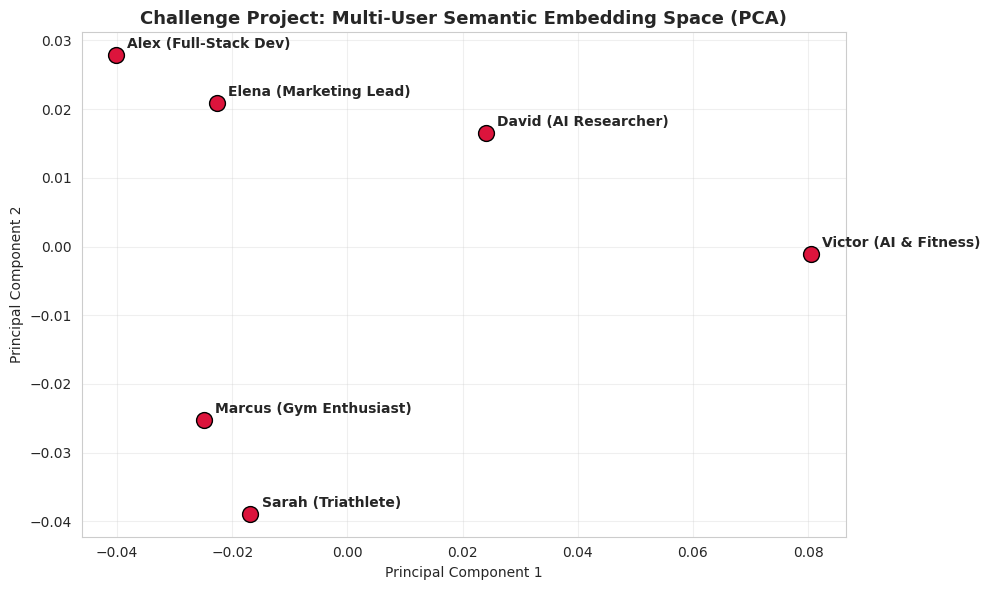

In [41]:
# ==========================================================
# CHALLENGE PROJECT: ENHANCED DIGITAL TWIN LANGUAGE SYSTEM
# ==========================================================
# 1. Multi-User Profile Corpus
user_corpus = {
    "Victor (AI & Fitness)": my_description,
    "Alex (Full-Stack Dev)": "Software engineer building web apps with TypeScript, React, and Python databases.",
    "Sarah (Triathlete)": "Endurance athlete focused on marathon training, cycling, and sports nutrition.",
    "David (AI Researcher)": "Deep learning researcher training foundation models, transformers, and neural networks.",
    "Elena (Marketing Lead)": "Brand marketing strategist analyzing digital consumer behavior and campaign metrics.",
    "Marcus (Gym Enthusiast)": "Fitness trainer focused on weight lifting, athletic performance, and outdoor workouts."
}

# 2. Encode all profiles into vector representations
names = list(user_corpus.keys())
user_vectors = np.array([twin_encoder.encode_user(user_corpus[name]) for name in names])

# 3. Connection Recommendation Engine (Cosine Similarity)
print("=" * 65)
print("DIGITAL TWIN CONNECTION RECOMMENDATIONS")
print("=" * 65)

for i, name in enumerate(names):
    sims = []
    for j, other_name in enumerate(names):
        if i == j:
            continue
        v1, v2 = user_vectors[i], user_vectors[j]
        cos_sim = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
        sims.append((other_name, cos_sim))

    sims.sort(key=lambda x: x[1], reverse=True)
    top_match, score = sims[0]
    print(f"User: {name:<26} -> Top Match: {top_match} (Score: {score:.3f})")

# 4. Filtered Interest Extraction for Victor's Profile (Excluding Stopwords)
stopwords = {'and', 'the', 'in', 'on', 'at', 'i', 'a', 'to', 'for', 'of', 'while', 'my'}
tokens = simple_tokenize(my_description)
token_ids = tokenizer.encode(my_description)
embedded = trained_embeddings.embed(token_ids)
norms = np.linalg.norm(embedded, axis=1)

unique_interests = []
for idx in np.argsort(norms)[::-1]:
    word = tokens[idx]
    if word not in stopwords and word not in unique_interests:
        unique_interests.append(word)
    if len(unique_interests) == 5:
        break

print("\n" + "=" * 65)
print(f"Clean Detected Key Interests: {unique_interests}")
print("=" * 65)

# 5. Visualize Multi-User Semantic Vector Space (PCA)
pca = PCA(n_components=2)
user_coords_2d = pca.fit_transform(user_vectors)

plt.figure(figsize=(10, 6))
plt.scatter(user_coords_2d[:, 0], user_coords_2d[:, 1], color='crimson', s=130, edgecolors='black', zorder=3)

for i, name in enumerate(names):
    plt.annotate(
        name,
        (user_coords_2d[i, 0], user_coords_2d[i, 1]),
        textcoords="offset points",
        xytext=(8, 5),
        fontsize=10,
        fontweight='bold'
    )

plt.title("Challenge Project: Multi-User Semantic Embedding Space (PCA)", fontsize=13, fontweight='bold')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()